# Bangladesh Road Accidents 2021–2026: Analysis

Uses the cleaned tables in `data/processed/` (built by `01_data_cleaning.ipynb`). All figures are Road Safety
Foundation (RSF) counts of accidents reported in the media.

1. Deaths by year
2. Deaths by vehicle type
3. Deaths by division
4. Time of year (month, season, Eid) and time of day
5. Key findings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

DATA = Path("../data/processed")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

# Chart palette (light mode)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CONTEXT = "#c3c2b7"   # de-emphasised bars
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SURFACE = "#fcfcfb"
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK,
    "axes.edgecolor": CONTEXT, "axes.labelcolor": INK2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 22, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "figure.dpi": 110,
})


def titled(ax, title, subtitle):
    ax.set_title(title)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom")


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


thousands = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

In [2]:
monthly = pd.read_csv(DATA / "monthly_national.csv")
annual = pd.read_csv(DATA / "annual_national.csv")
vehicle = pd.read_csv(DATA / "vehicle_deaths.csv")
division = pd.read_csv(DATA / "division.csv")
time_of_day = pd.read_csv(DATA / "time_of_day.csv")
eid = pd.read_csv(DATA / "eid_periods.csv")
population = pd.read_csv("../data/raw/division_population_2022.csv")

full_years = annual[annual["coverage"] == "full year"].copy()
full_years["year"] = full_years["year"].astype(int)

## 1. Deaths by year

RSF's annual reports give complete counts for 2021–2025. 2026 is still in progress, so it is compared with 2025
separately below, using only the months reported in both years.

In [3]:
yearly = full_years.set_index("year")[["accidents", "deaths", "injuries", "deaths_per_accident"]].copy()
yearly["deaths_per_day"] = (yearly["deaths"] / 365).round(1)
yearly["deaths_change_pct"] = (100 * yearly["deaths"].pct_change()).round(1)
yearly["accidents_change_pct"] = (100 * yearly["accidents"].pct_change()).round(1)
yearly.astype({"accidents": int, "deaths": int, "injuries": int})

,accidents,deaths,injuries,deaths_per_accident,deaths_per_day,deaths_change_pct,accidents_change_pct
year,,,,,,,
2021,5371,6284,7468,1.17,17.2,NaN,NaN
2022,6829,7713,12615,1.13,21.1,22.7,27.1
2023,6911,6524,11407,0.94,17.9,-15.4,1.2
2024,6927,7294,12019,1.05,20.0,11.8,0.2
2025,7584,7359,16476,0.97,20.2,0.9,9.5


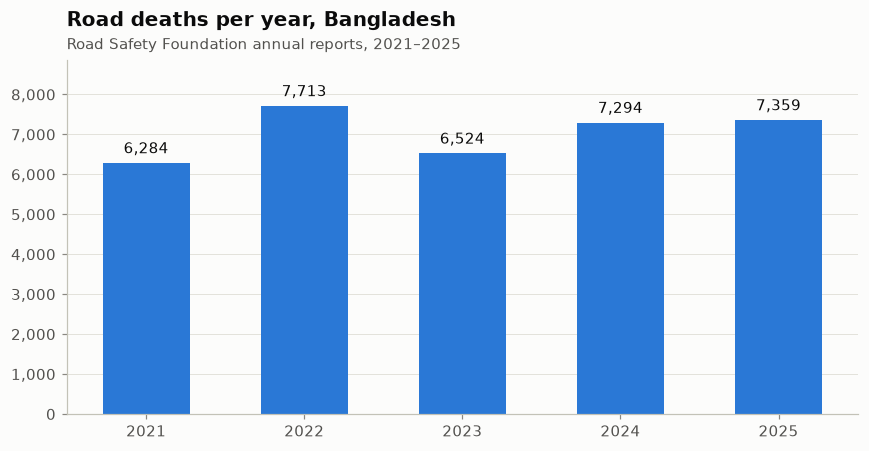

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(yearly.index, yearly["deaths"], width=0.55, color=BLUE)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in yearly["deaths"]], padding=4, color=INK, fontsize=10)
ax.set_ylim(0, yearly["deaths"].max() * 1.15)
ax.yaxis.set_major_formatter(thousands)
ax.grid(axis="x", visible=False)
ax.set_xticks(yearly.index)
titled(ax, "Road deaths per year, Bangladesh", "Road Safety Foundation annual reports, 2021–2025")
save(fig, "01_deaths_per_year")

Accidents, deaths and injuries indexed to 2021 = 100, so all three can share one axis:

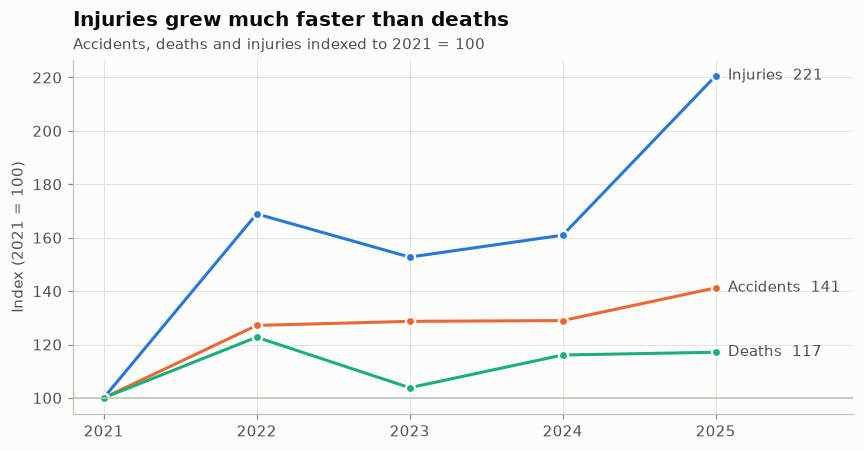

In [5]:
indexed = 100 * yearly[["accidents", "deaths", "injuries"]] / yearly[["accidents", "deaths", "injuries"]].iloc[0]

fig, ax = plt.subplots(figsize=(8, 4.2))
for col, color in zip(["injuries", "accidents", "deaths"], [BLUE, ORANGE, AQUA]):
    ax.plot(indexed.index, indexed[col], color=color, lw=2, marker="o", ms=6, mec=SURFACE, mew=1.5)
    ax.annotate(f"{col.capitalize()}  {indexed[col].iloc[-1]:.0f}", (indexed.index[-1], indexed[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=INK2, fontsize=9.5)
ax.axhline(100, color=CONTEXT, lw=1)
ax.set_xticks(indexed.index)
ax.set_xlim(2020.8, 2025.9)
ax.set_ylabel("Index (2021 = 100)")
titled(ax, "Injuries grew much faster than deaths", "Accidents, deaths and injuries indexed to 2021 = 100")
save(fig, "02_indexed_trend")

### 2026 so far vs 2025 (same months)

Like-for-like: only months that have an RSF report in **both** 2025 and 2026.

In [6]:
m = monthly[monthly["reported"]]
both = sorted(set(m.loc[m["year"] == 2025, "month"]) & set(m.loc[m["year"] == 2026, "month"]))
ytd = (
    m[m["year"].isin([2025, 2026]) & m["month"].isin(both)]
    .groupby("year")[["accidents", "deaths", "injuries"]].sum()
)
ytd.loc["change_pct"] = (100 * (ytd.loc[2026] / ytd.loc[2025] - 1)).round(1)
print("Months compared:", [pd.Timestamp(2000, mo, 1).strftime("%b") for mo in both])
ytd

Months compared: ['Jan', 'Mar', 'Apr', 'Jun', 'Jul', 'Aug', 'Sep']


,accidents,deaths,injuries
year,,,
2025,3830.0,3759.0,7651.0
2026,3483.0,3181.0,6652.0
change_pct,-9.1,-15.4,-13.1


### Who dies

The annual reports also break deaths down by victim group:

In [7]:
victims = full_years.set_index("year")[["deaths", "pedestrian_deaths", "women_deaths", "children_deaths"]]
shares = (100 * victims[["pedestrian_deaths", "women_deaths", "children_deaths"]].div(victims["deaths"], axis=0)).round(1)
shares.columns = ["pedestrians_%", "women_%", "children_%"]
victims.join(shares)

,deaths,pedestrian_deaths,women_deaths,children_deaths,pedestrians_%,women_%,children_%
year,,,,,,,
2021,6284.0,1523.0,927.0,734.0,24.2,14.8,11.7
2022,7713.0,NaN,1061.0,1143.0,NaN,13.8,14.8
2023,6524.0,NaN,974.0,1128.0,NaN,14.9,17.3
2024,7294.0,1535.0,893.0,1152.0,21.0,12.2,15.8
2025,7359.0,1564.0,962.0,1008.0,21.3,13.1,13.7
